# A JAX model between eagle launches

Your JAX model decides, eagle steps 512 oscillators, and the two agree to rounding on the CPU and on a GPU.

```python
node = eagle_jax.node(model, reads={"x": x, "v": v}, writes={"corr": corr})   # your JAX model, as a graph node
graph = eagle.Graph().add_node(node, name="model").add(osc.bind(...), name="osc").build()
graph.launch(200)                                                             # model, step, model, step, ...
```

**Time:** ~5 min · **Runs on:** CPU, GPU if visible (picked up automatically) · **You need:** eagle, hawk and JAX

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by docs/_tools/nb_colab_setup.py (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    from packaging.version import Version

    try:
        old = Version(importlib.metadata.version("jax")) < Version("0.11.2")
    except importlib.metadata.PackageNotFoundError:
        old = True
    if old:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"jax{extra}>=0.11.2"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style
plot_style()

## Your model, their step

The model is a small network written in `jax.numpy`. It looks at each oscillator's position and velocity and returns
a correction. The step that moves the oscillators is a hawk kernel that takes that correction as an input plane.
Nothing here is specific to eagle yet: `model` is an ordinary jitted JAX function.

In [3]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # leave GPU memory for your other libraries
import jax
import jax.numpy as jnp
import numpy as np

jax.config.update("jax_enable_x64", True)

import hawk
from hawk import Mutable, Param, Scalar, Terminated

import eagle
import eagle.plan
from eagle.frameworks import jax as eagle_jax

N, DT, C = 512, 0.01, 0.3
k1, k2 = jax.random.split(jax.random.key(0))
W1, W2 = 0.5 * jax.random.normal(k1, (2, 8)), 0.5 * jax.random.normal(k2, (8,))


@jax.jit
def model(x, v):
    return jnp.tanh(jnp.stack([x, v], 1) @ W1) @ W2          # (N,) correction per oscillator


@hawk.kernel(steps=1)
def osc(dt: Param, c: Param, t_final: Scalar, corr: Scalar, terminated: Terminated,
        x: Mutable[Scalar], v: Mutable[Scalar], t: Mutable[Scalar]):
    vn = v + dt * (-x - c * v + corr * v)
    x = x + dt * v
    v = vn
    tn = t + dt
    t = tn
    terminated = tn >= t_final        # each oscillator stops at its own final time

## One graph, two owners

Where the planes live decides where the step runs: NumPy arrays for the CPU, CuPy arrays for a GPU. The same lines
build the graph either way, with the JAX node first and the kernel after it, so each launch is one model call and
one step.

In [4]:
gpu = jax.default_backend() == "gpu"
if gpu:
    import cupy as xp
else:
    xp = np
(plan,) = eagle.plan.auto([osc], targets=("cuda" if gpu else "host",))

start = dict(x=np.linspace(0.5, 1.5, N), v=np.linspace(-0.2, 0.3, N), t=np.zeros(N),
             corr=np.zeros(N), t_final=np.linspace(0.5, 2.0, N))
planes = {name: xp.asarray(a).copy() for name, a in start.items()}
mask = xp.zeros(N, bool)

node = eagle_jax.node(model, reads={"x": planes["x"], "v": planes["v"]}, writes={"corr": planes["corr"]})
graph = (eagle.Graph()
         .add_node(node, name="model")
         .add(plan.bind(dt=DT, c=C, terminated=mask, finished_count=xp.zeros(1, np.uint32), **planes), name="osc")
         .build())
graph.schedule

('eager_stream', 'capture')

`schedule` says how each piece runs. On a GPU the middle entry reads `eager_stream`: JAX runs on a stream of its own
(a queue of GPU work), eagle orders it between the two kernel segments on the device, and the host never waits. On the
CPU there are no streams, so the whole graph is one host schedule.

## Run it, and check it against plain JAX

We launch one step at a time and keep five oscillators' positions to draw. The reference is the same loop written
entirely in `jax.numpy`, with a `where` that freezes each oscillator once it has stopped.

In [5]:
def host(a):
    return a.get() if hasattr(a, "get") else np.asarray(a)


track = [host(planes["x"])[::128].copy()]
for _ in range(200):                      # 200 steps of 0.01 reach the longest final time, 2.0
    graph.launch()
    track.append(host(planes["x"])[::128].copy())
graph.synchronize()


@jax.jit
def reference_step(x, v, t, done):
    vn = v + DT * (-x - C * v + model(x, v) * v)
    xn, tn = x + DT * v, t + DT
    return (jnp.where(done, x, xn), jnp.where(done, v, vn), jnp.where(done, t, tn),
            done | (tn >= jnp.asarray(start["t_final"])))


state = (jnp.asarray(start["x"]), jnp.asarray(start["v"]), jnp.zeros(N), jnp.zeros(N, bool))
ref_track = [np.asarray(state[0])[::128]]
for _ in range(200):
    state = reference_step(*state)
    ref_track.append(np.asarray(state[0])[::128])

err = float(np.abs(host(planes["x"]) - np.asarray(state[0])).max())
print(f"all stopped: {bool(host(mask).all())}; largest difference from plain JAX: {err:.1e}")
assert err < 1e-12

all stopped: True; largest difference from plain JAX: 6.7e-16


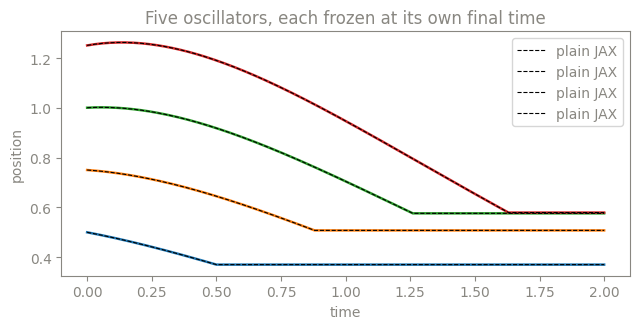

In [6]:
import matplotlib.pyplot as plt

time = np.arange(201) * DT
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(time, np.array(track), lw=1.8)
ax.plot(time, np.array(ref_track), "k--", lw=0.8, label="plain JAX")
ax.set(xlabel="time", ylabel="position", title="Five oscillators, each frozen at its own final time")
ax.legend(loc="upper right")
plt.tight_layout()

The solid lines are eagle stepping with your model in the loop, the dashed ones the all-JAX loop: they sit on top
of each other, and each curve goes flat where its oscillator stopped.

## Why the results stay correct

JAX hands the model's result to eagle without copying. eagle then copies it into `corr` on the node's own stream, and
holds on to JAX's buffer until that copy has really run, so JAX may reuse its memory for the next call without racing
the copy. You write nothing for this; it is the reason `node` exists instead of a bare callback. Jit the model, as
above: an un-jitted call spends host time on every launch.

## Inside `until_done`

On the CPU the same node and kernel also run inside `until_done`, which stops each sample as it finishes. On a GPU
that loop is one device graph, so a JAX node is refused with a message that says so.

In [7]:
try:
    again = {name: xp.asarray(a).copy() for name, a in start.items()}
    inner = eagle_jax.node(model, reads={"x": again["x"], "v": again["v"]}, writes={"corr": again["corr"]})
    report = eagle.until_done([inner, plan], max_steps=400, dt=DT, c=C, terminated=xp.zeros(N, bool), **again).run()
    print("until_done:", report.steps, "steps,", "done" if report.done else "not done")
except ValueError as refusal:
    print(str(refusal).split(": run host")[0])

eagle.until_done: node 'opaque_stream' runs on the host each launch, but a stepping loop is one device graph


When a JAX call has to read values back on the host, use `opaque(fn, eager=True)` instead: it works anywhere, at the
price of waiting for the device twice per launch. [Your own code in the graph](../graph_model) lays out all three tiers.

## Limits

- <!-- limit: jax-node-loop --> On a GPU a JAX node runs between launches, not inside `until_done`'s one device graph, because XLA owns its own memory and cannot be captured (XLA's design): drive the graph with your own loop, as this page does, or put the batch inside `jit` (tutorial 18).

## Next

- [The eagle batch inside `jit`](18_the_eagle_batch_inside_jit): the other direction, when JAX owns the loop.
- [eagle inside your JAX program](../../interop/jax): what crosses, what is refused, the limits.